# Предсказание калорийности блюд

Нужно по фото блюда и списку ингредиентов предсказать `total_calories`. Это регрессия, не классификация.

Цель: MAE меньше 50 на `test`.

## EDA

Сначала смотрю таблицы и распределения. Технические id вроде `ingr_0000000122` заменяю на нормальные названия из `ingredients.csv`, иначе BERT не поймет, что за продукты.


In [1]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "scripts").exists():
    PROJECT_ROOT = Path("/Users/krlssnov/Desktop/ЯПрактикум/VS Code/DL/project_sprint4")
    os.chdir(PROJECT_ROOT)

sys.path.append(str(PROJECT_ROOT / "scripts"))

from config import Config
from dataset import prepare_dish_table

cfg = Config()
print("DATA_DIR:", Path(cfg.DISH_CSV).parent)
print("IMAGES_DIR:", cfg.IMAGES_DIR)


/Users/krlssnov/Desktop/ЯПрактикум/VS Code/DL/.venv/lib/python3.10/site-packages/requests/__init__.py:113: RequestsDependencyWarning: urllib3 (2.4.0) or chardet (7.4.3)/charset_normalizer (3.4.2) doesn't match a supported version!
  warnings.warn(
/Users/krlssnov/Desktop/ЯПрактикум/VS Code/DL/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


DATA_DIR: /Users/krlssnov/Desktop/ЯПрактикум/VS Code/DL/project_sprint4/data
IMAGES_DIR: /Users/krlssnov/Desktop/ЯПрактикум/VS Code/DL/project_sprint4/data/images


In [2]:
dish_raw = pd.read_csv(cfg.DISH_CSV)
ingr_raw = pd.read_csv(cfg.INGR_CSV)

print("dish.csv:", dish_raw.shape, list(dish_raw.columns))


dish.csv: (3262, 5) ['dish_id', 'total_calories', 'total_mass', 'ingredients', 'split']


**По dish.csv.** 3262 строки, колонки ожидаемые: `dish_id`, `total_calories`, `total_mass`, `ingredients`, `split`. Цель сразу видна - калории. Масса тоже лежит рядом.


In [3]:
print("ingredients.csv:", ingr_raw.shape, list(ingr_raw.columns))

ingredients.csv: (555, 2) ['id', 'ingr']


**По ingredients.csv.** Всего 555 ингредиентов, две колонки: числовой `id` и название `ingr`.


In [4]:
display(dish_raw.head(3))

,dish_id,total_calories,total_mass,ingredients,split
0,dish_1561662216,300.794281,193.0,ingr_0000000508;ingr_0000000122;ingr_000000002...,test
1,dish_1561662054,419.438782,292.0,ingr_0000000312;ingr_0000000026;ingr_000000002...,train
2,dish_1562008979,382.936646,290.0,ingr_0000000448;ingr_0000000520;ingr_000000046...,test


**Что видно в head dish.** В `ingredients` идет длинная строка с `ingr_000...` через точку с запятой. Split уже размечен на train/test прямо в таблице.


In [5]:
display(ingr_raw.head(5))

,id,ingr
0,1,cottage cheese
1,2,strawberries
2,3,garden salad
3,4,bacon
4,5,potatoes


**Что видно в head ingredients.** Обычные продукты: cottage cheese, strawberries, bacon и т.д. Значит после джойна текст станет читаемым, а не набором кодов.


In [6]:
print("split:\n", dish_raw["split"].value_counts())

split:
 split
train    2755
test      507
Name: count, dtype: int64


**Про split.** Train 2755, test 507. Отдельного val в файле нет, поэтому валидацию позже отрезаем от train (примерно 15%). Test трогать при обучении нельзя, он только для финальной проверки.


In [7]:
table = prepare_dish_table(cfg)
print("после замены id на названия и проверки картинок:", table.shape)

после замены id на названия и проверки картинок: (3262, 6)


**После prepare_dish_table.** Строк осталось 3262, то есть картинки нашлись у всех блюд, ничего не выкинули. Плюс должна появиться колонка `text` с названиями ингредиентов.


In [8]:
display(table[["dish_id", "total_calories", "total_mass", "text", "split"]].head(5))

,dish_id,total_calories,total_mass,text,split
0,dish_1561662216,300.794281,193.0,"soy sauce, garlic, white rice, parsley, onions...",test
1,dish_1561662054,419.438782,292.0,"pepper, white rice, mixed greens, garlic, soy ...",train
2,dish_1562008979,382.936646,290.0,"jalapenos, lemon juice, pork, wheat berry, cab...",test
3,dish_1560455030,20.590000,103.0,"cherry tomatoes, cucumbers, baby carrots",train
4,dish_1558372433,74.360001,143.0,deprecated,train


**Собранная таблица.** Теперь рядом калории, масса, нормальный текст и split. На этом уже можно строить датасет: картинка по `dish_id`, текст в BERT, масса в голову модели.


In [9]:
print("пример текста:", table.loc[0, "text"][:200])

пример текста: soy sauce, garlic, white rice, parsley, onions, brown rice, vinegar, apple, mixed greens, sugar, salt, lemon juice, olive oil, pork, bok choy, pepper, millet


**Пример текста.** Получился нормальный список продуктов на английском. Для BERT это уже осмысленный вход. Длина у блюд разная: где-то коротко, где-то длинный перечень, поэтому в токенизаторе нужен запас по `max_length`.


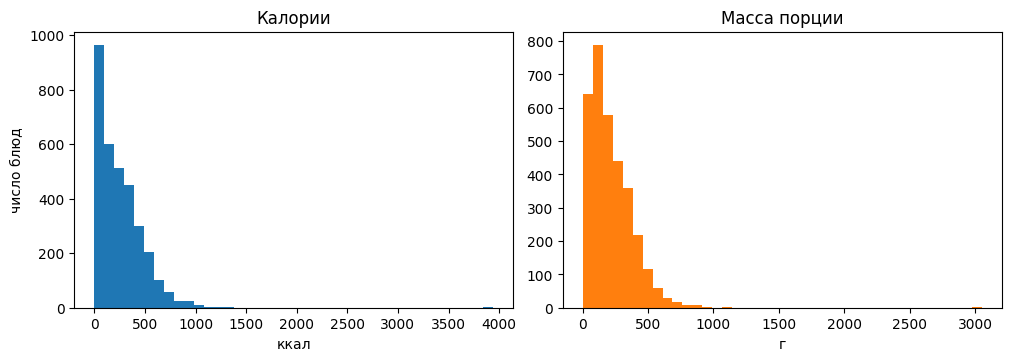

       total_calories  total_mass
count         3262.00     3262.00
mean           255.01      214.98
std            219.64      161.50
min              0.00        1.00
25%             80.11       92.00
50%            209.11      177.00
75%            375.12      305.00
max           3943.33     3051.00
корреляция калории–масса: 0.76


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), layout="constrained")
axes[0].hist(table["total_calories"], bins=40, color="tab:blue")
axes[0].set(title="Калории", xlabel="ккал", ylabel="число блюд")
axes[1].hist(table["total_mass"], bins=40, color="tab:orange")
axes[1].set(title="Масса порции", xlabel="г")
plt.show()

print(table[["total_calories", "total_mass"]].describe().round(2))
print("корреляция калории–масса:", table["total_calories"].corr(table["total_mass"]).round(3))


**По гистограммам и describe.** Средние калории около 255, медиана ниже, значит есть правый хвост с очень калорийными блюдами. Масса тоже размазана от крошечных порций до больших. Корреляция калорий с массой около 0.76, связь сильная. Если модель массу проигнорирует, по хвосту она почти наверняка провалится.


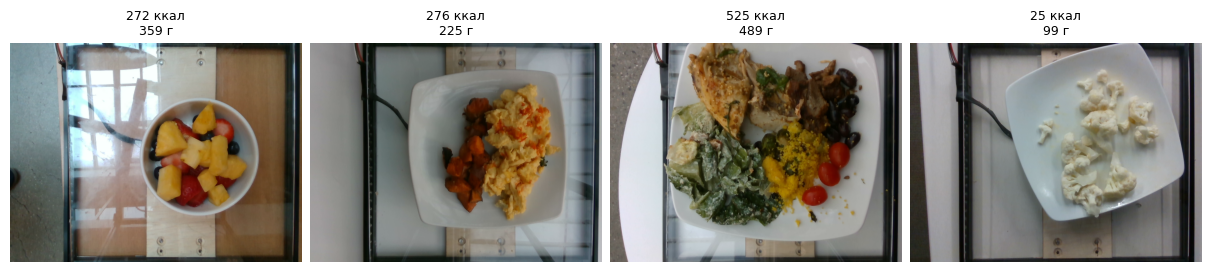

['berries, pineapple, cottage cheese', 'sweet potato, scrambled eggs', 'shallots, arugula, pepper, quinoa, mayonnaise, couscous, brussels sprouts, pork, wheat berry, thyme, lemon juice, caesar salad, salt, garlic, carrot, cherry tomatoes, jalapenos, olive oil, parsley, cabbage, olives', 'cauliflower']


In [11]:
sample = table.sample(4, random_state=cfg.SEED)
fig, axes = plt.subplots(1, 4, figsize=(12, 3), layout="constrained")
for ax, (_, row) in zip(axes, sample.iterrows()):
    img = Image.open(Path(cfg.IMAGES_DIR) / row["dish_id"] / "rgb.png")
    ax.imshow(img)
    ax.set_title(f"{row['total_calories']:.0f} ккал\n{row['total_mass']:.0f} г", fontsize=9)
    ax.axis("off")
plt.show()
print(sample["text"].tolist())


**По случайным фото.** Еда разная: простой творог с ягодами и более сложные тарелки с кучей ингредиентов. По одному кадру граммы и жирность не всегда очевидны. Поэтому в модели оставляю три сигнала сразу: фото, текст состава и массу.

**Как дальше обучаем.** Регрессия, голова на 1 выход, лосс L1. Картинка EfficientNet-B0, текст BERT, дальше проекции и фьюжн. Калории считаю как плотность * масса, иначе сеть залипает около среднего. Размораживаю хвосты энкодеров, 12 эпох, MPS, batch 4.


## Пайплайн и обучение

Сборка модели и цикл лежат в `scripts/utils.py` в `train(config)`. Там DataLoader, AdamW по всем блокам и сохранение лучших весов по val MAE.


In [12]:
import torch
from utils import get_device, train

print("torch:", torch.__version__)
print("device:", get_device())
print("BATCH_SIZE:", cfg.BATCH_SIZE, "EPOCHS:", cfg.EPOCHS)
print("SAVE_PATH:", cfg.SAVE_PATH)


torch: 2.7.0
device: mps
BATCH_SIZE: 4 EPOCHS: 12
SAVE_PATH: /Users/krlssnov/Desktop/ЯПрактикум/VS Code/DL/project_sprint4/artifacts/best_model.pth


**Перед запуском.** Torch видит `mps`, то есть обучение пойдет на GPU Mac, не на cpu. Batch 4 и 12 эпох как в конфиге. Чекпоинт будет писаться в `artifacts/best_model.pth`.


In [13]:
model, best_val_mae = train(cfg)
print("лучшая Val MAE:", round(best_val_mae, 3))


device: mps
Разморожен слой: encoder.layer.8.attention.self.query.weight
Разморожен слой: encoder.layer.8.attention.self.query.bias
Разморожен слой: encoder.layer.8.attention.self.key.weight
Разморожен слой: encoder.layer.8.attention.self.key.bias
Разморожен слой: encoder.layer.8.attention.self.value.weight
Разморожен слой: encoder.layer.8.attention.self.value.bias
Разморожен слой: encoder.layer.8.attention.output.dense.weight
Разморожен слой: encoder.layer.8.attention.output.dense.bias
Разморожен слой: encoder.layer.8.attention.output.LayerNorm.weight
Разморожен слой: encoder.layer.8.attention.output.LayerNorm.bias
Разморожен слой: encoder.layer.8.intermediate.dense.weight
Разморожен слой: encoder.layer.8.intermediate.dense.bias
Разморожен слой: encoder.layer.8.output.dense.weight
Разморожен слой: encoder.layer.8.output.dense.bias
Разморожен слой: encoder.layer.8.output.LayerNorm.weight
Разморожен слой: encoder.layer.8.output.LayerNorm.bias
Разморожен слой: encoder.layer.9.attention.s

**Вывод по обучению.**

Учился на mps, train 2342, val 413. Разморозил около 33 млн параметров из 114 млн. Это обычный fine-tuning: всю сеть с нуля на таком объеме нет смысла мучить.

По логу:
- эпоха 0: train MAE ~98, val ~75
- уже к 2-й эпохе val около 48, то есть порог 50 на валидации появляется рано
- лучший чекпоинт на эпохе 7: val MAE ~32.0
- потом train еще чуть падает, val начинает подрагивать

Сильного переобучения не видно, но после 7-й эпохи val почти не улучшается. Поэтому в файл сохраняется лучший чекпоинт, а не последняя эпоха. L1 и MAE идут рядом, это логично.


## Валидация на test

Беру `artifacts/best_model.pth`, считаю MAE на `split == test` и смотрю 5 блюд с самой большой ошибкой.


In [14]:
from functools import partial

import torch.nn as nn
from torch.utils.data import DataLoader
from transformers import AutoTokenizer

from dataset import MultimodalDataset, collate_fn, get_transforms
from utils import MultimodalModel, get_device

device = get_device()
model = MultimodalModel(cfg).to(device)
state = torch.load(cfg.SAVE_PATH, map_location=device)
model.load_state_dict(state)
model.eval()

table = prepare_dish_table(cfg)
test_df = table[table["split"] == "test"].reset_index(drop=True)
tokenizer = AutoTokenizer.from_pretrained(cfg.TEXT_MODEL_NAME)
test_ds = MultimodalDataset(test_df, cfg, get_transforms(cfg, ds_type="val"))
test_loader = DataLoader(
    test_ds,
    batch_size=cfg.BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    collate_fn=partial(collate_fn, tokenizer=tokenizer, max_length=cfg.MAX_LENGTH),
)

rows = []
with torch.no_grad():
    for batch in test_loader:
        preds = model(
            input_ids=batch["input_ids"].to(device),
            attention_mask=batch["attention_mask"].to(device),
            image=batch["image"].to(device),
            mass=batch["mass"].to(device),
        ).cpu().numpy()
        y = batch["label"].numpy()
        for i, dish_id in enumerate(batch["dish_id"]):
            rows.append({
                "dish_id": dish_id,
                "text": batch["text"][i],
                "y": float(y[i]),
                "pred": float(preds[i]),
                "abs_err": float(abs(preds[i] - y[i])),
                "mass": float(batch["mass"][i]),
            })

pred_df = pd.DataFrame(rows)
test_mae = pred_df["abs_err"].mean()
print(f"Test MAE: {test_mae:.3f}  (цель < 50: {'да' if test_mae < 50 else 'нет'})")
display(pred_df[["y", "pred", "abs_err"]].describe().round(2))


Test MAE: 44.853  (цель < 50: да)


,y,pred,abs_err
count,507.00,507.00,507.00
mean,255.47,230.80,44.85
std,212.24,180.47,69.39
min,0.00,0.24,0.00
25%,74.36,75.77,4.49
50%,226.01,201.70,17.65
75%,369.68,334.68,51.36
max,1050.51,913.03,489.93


**По test MAE.** Получилось 44.853. Цель - меньше 50, значит порог взят. Запас небольшой, поэтому отдельно смотрю, на каких блюдах модель ошибается сильнее всего.


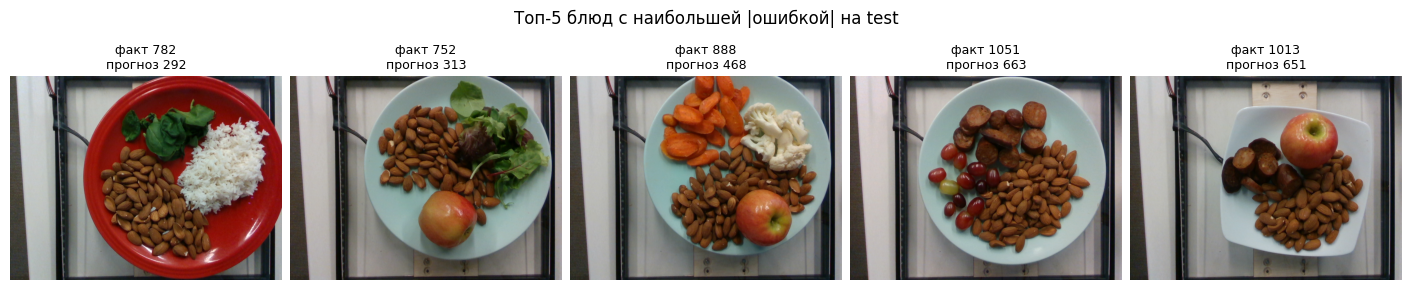

------------------------------------------------------------
dish_id: dish_1558549806
ингредиенты: almonds, white rice, spinach (raw)
масса 203 г | факт 782.0 ккал | прогноз 292.0 | |err| 489.9
------------------------------------------------------------
dish_id: dish_1558630325
ингредиенты: apple, garden salad, almonds
масса 269 г | факт 751.5 ккал | прогноз 312.8 | |err| 438.7
------------------------------------------------------------
dish_id: dish_1558720236
ингредиенты: apple, carrot, cauliflower, almonds
масса 407 г | факт 887.8 ккал | прогноз 467.6 | |err| 420.2
------------------------------------------------------------
dish_id: dish_1558375886
ингредиенты: almonds, sausage, grapes
масса 277 г | факт 1050.5 ккал | прогноз 663.4 | |err| 387.1
------------------------------------------------------------
dish_id: dish_1558373159
ингредиенты: sausage, deprecated, almonds
масса 334 г | факт 1013.3 ккал | прогноз 650.6 | |err| 362.8


In [15]:
top5 = pred_df.sort_values("abs_err", ascending=False).head(5)

fig, axes = plt.subplots(1, 5, figsize=(14, 3.2), layout="constrained")
for ax, (_, row) in zip(axes, top5.iterrows()):
    img = Image.open(Path(cfg.IMAGES_DIR) / row["dish_id"] / "rgb.png")
    ax.imshow(img)
    ax.set_title(f"факт {row['y']:.0f}\nпрогноз {row['pred']:.0f}", fontsize=9)
    ax.axis("off")
plt.suptitle("Топ-5 блюд с наибольшей |ошибкой| на test")
plt.show()

for _, row in top5.iterrows():
    print("-" * 60)
    print("dish_id:", row["dish_id"])
    print("ингредиенты:", row["text"][:180])
    print(f"масса {row['mass']:.0f} г | факт {row['y']:.1f} ккал | прогноз {row['pred']:.1f} | |err| {row['abs_err']:.1f}")


**Вывод по топ ошибкам.**

Почти все крупные промахи связаны с орехами, колбасой и вообще жирным составом. Факт 750-1050 ккал, а модель недооценивает. Например, almonds + rice + spinach: 782 против 292. На sausage + almonds уже лучше, чем в первом прогоне (около 650, а не 360), но ошибка все равно большая.

Кажется, средние блюда модель уже более-менее тянет, а хвост все еще сложный. На фото такие порции не всегда выглядят "на тысячу калорий", плюс в тексте попадается странное `deprecated`. Полностью вычистить такие кейсы без перекоса на обычные блюда сложно.
